# DES Y6 data products: review

A read-only look at every product of `msfm.apps.products.desy6` (`data/desy6/README.md`).
It writes nothing. The checks that gate a product run inside the steps; this notebook is for looking, and for the two
questions the steps cannot settle on their own:

- the coverage threshold of the footprint;
- the shear convention: κ_E × δ_g must be positive and κ_B × δ_g null, the decisive test for Y3.

Run it after the steps `nz`, `pixels`, `maps`, `values`, `noise` and `sc_bias`, in `torch_env` (healpy, h5py,
matplotlib, msfm from this checkout). The cache of `maps` and the noise file are gitignored, and `values --check` reads
the catalog. Where those are missing, only the sections on provenance, n(z), the footprint and the source clustering
grid run.

In [ ]:
from pathlib import Path

import h5py
import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
import yaml

import msfm

# REPO comes from the msfm import, so an msfm installed from another clone would read that clone's configs and data
REPO = Path(msfm.__file__).resolve().parents[1]
assert REPO in [Path.cwd().resolve(), *Path.cwd().resolve().parents], f"msfm comes from {REPO}, not this checkout"

from msfm.apps.products import desy6
from msfm.utils import catalog, catalog_desy6, cosmogrid, files, filenames, lensing, source_clustering_bias as scb

CONFIG = REPO / "configs/desy6/v1/v1.yaml"
conf = files.load_config(str(CONFIG))

n_side = conf["analysis"]["n_side"]
n_pix = hp.nside2npix(n_side)
pix_area = hp.nside2pixarea(n_side, degrees=True)

# every product holds all survey bins; the config's z_bins select from them
survey_labels = {"metacal": [f"metacal{i}" for i in range(1, 5)], "maglim": [f"maglim{i}" for i in range(1, 7)]}
used = {sample: conf["survey"][sample]["z_bins"] for sample in survey_labels}
print(used)

## Provenance

The steps run with `--provenance`: on which commit, and whether every recorded output is still the file on disk.

In [2]:
with open(REPO / conf["files"]["provenance"]) as f:
    prov = yaml.safe_load(f)["steps"]

for step, record in prov.items():
    print(f"{step:8s} {record['date']}  msfm {record['msfm_commit'][:10]}")
    for out in record["outputs"]:
        path = REPO / out["path"]
        state = "missing" if not path.exists() else ("ok" if desy6._sha256(path) == out["sha256"] else "CHANGED")
        print(f"    {state:8s} {out['path']}")

# a step run without --provenance leaves no record
print("no record:", [step for step in desy6.STEP_ORDER if step not in prov])

nz       2026-11-18T13:43:42+01:00  msfm 73f58dcd0a
    ok       data/desy6/redshift_distributions/desy6_nz_metacal_bin1.txt
    ok       data/desy6/redshift_distributions/desy6_nz_metacal_bin2.txt
    ok       data/desy6/redshift_distributions/desy6_nz_metacal_bin3.txt
    ok       data/desy6/redshift_distributions/desy6_nz_metacal_bin4.txt
    ok       data/desy6/redshift_distributions/desy6_nz_maglim_bin1.txt
    ok       data/desy6/redshift_distributions/desy6_nz_maglim_bin2.txt
    ok       data/desy6/redshift_distributions/desy6_nz_maglim_bin3.txt
    ok       data/desy6/redshift_distributions/desy6_nz_maglim_bin4.txt
    ok       data/desy6/redshift_distributions/desy6_nz_maglim_bin5.txt
    ok       data/desy6/redshift_distributions/desy6_nz_maglim_bin6.txt
no record: ['pixels', 'maps', 'values', 'noise', 'sc_bias']


## n(z)

The fiducial n(z) of the 3x2pt FITS. Dotted lines are survey bins the config does not use. The grid starts at
z = 0.00, unlike Y3's 0.005.

grid starts at z = 0.0; n(z) there: {'metacal1': np.float64(0.0), 'metacal2': np.float64(0.0), 'metacal3': np.float64(0.0), 'metacal4': np.float64(0.0), 'maglim1': np.float64(0.0), 'maglim2': np.float64(0.0), 'maglim3': np.float64(0.0), 'maglim4': np.float64(0.0), 'maglim5': np.float64(0.0), 'maglim6': np.float64(0.0)}


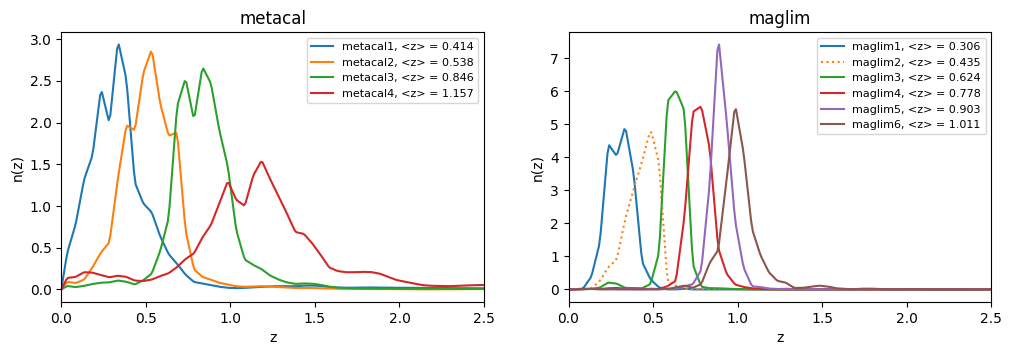

In [3]:
nz_dir = str(REPO / conf["dirs"]["redshift_distributions"])
mean_z, nz_at_grid_start = {}, {}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
for ax, (sample, labels) in zip(axes, survey_labels.items()):
    for i_bin, label in enumerate(labels, start=1):
        z, nz = np.loadtxt(filenames.get_filename_z_distribution(nz_dir, sample, i_bin, prefix=conf["survey"]["name"].lower())).T
        mean_z[label], nz_at_grid_start[label] = np.sum(z * nz) / np.sum(nz), nz[0]
        style = "-" if label in used[sample] else ":"
        ax.plot(z, nz, style, label=f"{label}, <z> = {mean_z[label]:.3f}")
    ax.set(xlabel="z", ylabel="n(z)", title=sample, xlim=(0, 2.5))
    ax.legend(fontsize=8)

print(f"grid starts at z = {z[0]}; n(z) there: {nz_at_grid_start}")

## Footprint and the coverage threshold

The pixel file stores the rotated coverage of every nside-512 pixel (`footprint/coverage`), so the threshold can be
re-derived here without healsparse. As in Y3 (0.72), it is chosen so the footprint area matches the mask area.
Pixels below the threshold leave the footprint, at its edges and as interior holes (pixels below the threshold whose
eight neighbours are all in the footprint). About 11% of the mask area is lost this way (Y3: 8%), mostly through the
lower coverage of the Y6 pixels; the number of holes is similar to Y3's.

In [4]:
with h5py.File(REPO / conf["files"]["pixels"], "r") as f:
    attrs = dict(f.attrs)
    coverage = f["footprint/coverage"][:].astype(np.float64)
    patches = f["footprint/patches"][:]
    data_vec = f["data_vec"][:]
for key, value in attrs.items():
    print(f"{key}: {value}")

threshold = attrs["coverage_threshold"]
footprint = patches[0]
in_footprint = np.zeros(n_pix, dtype=bool)
in_footprint[footprint] = True
print(
    f"\nfootprint: {footprint.size} pixels, {footprint.size * pix_area:.1f} deg^2 (mask {attrs['area_deg2']:.3f}), "
    f"mean coverage {coverage[footprint].mean():.4f}; data vector {data_vec.size} pixels"
)
print(
    f"mask area in the footprint {coverage[footprint].sum() * pix_area:.1f} deg^2, "
    f"outside {coverage[~in_footprint].sum() * pix_area:.1f} deg^2, "
    f"fraction inside {coverage[footprint].sum() / coverage.sum():.4f}"
)

# holes: below the threshold, but surrounded by the footprint
neighbours = hp.get_all_neighbours(n_side, np.arange(n_pix))
surrounded = np.all(in_footprint[neighbours] | (neighbours < 0), axis=0)
holes = surrounded & ~in_footprint
print(f"{holes.sum()} holes; their coverage: {np.round(np.sort(coverage[holes]), 3)[:30]}")

area_deg2: 4031.03590997686
coverage_threshold: 0.73
info: DES Y6 jointmask_DESY6_2024-06-04.hsp, rotated by analysis.footprint.rotation, at nside 512. Written by msfm.apps.products.desy6 pixels
rotate_nside: 4096
rotation_y_rad: -0.125
rotation_z_rad: -1.22

footprint: 309226 pixels, 4055.2 deg^2 (mask 4031.036), mean coverage 0.8840; data vector 457728 pixels
mask area in the footprint 3584.6 deg^2, outside 446.4 deg^2, fraction inside 0.8893


5922 holes; their coverage: [0.014 0.027 0.048 0.054 0.054 0.067 0.069 0.07  0.114 0.121 0.132 0.133
 0.144 0.147 0.149 0.151 0.152 0.153 0.155 0.157 0.159 0.162 0.163 0.166
 0.168 0.172 0.174 0.176 0.18  0.181]


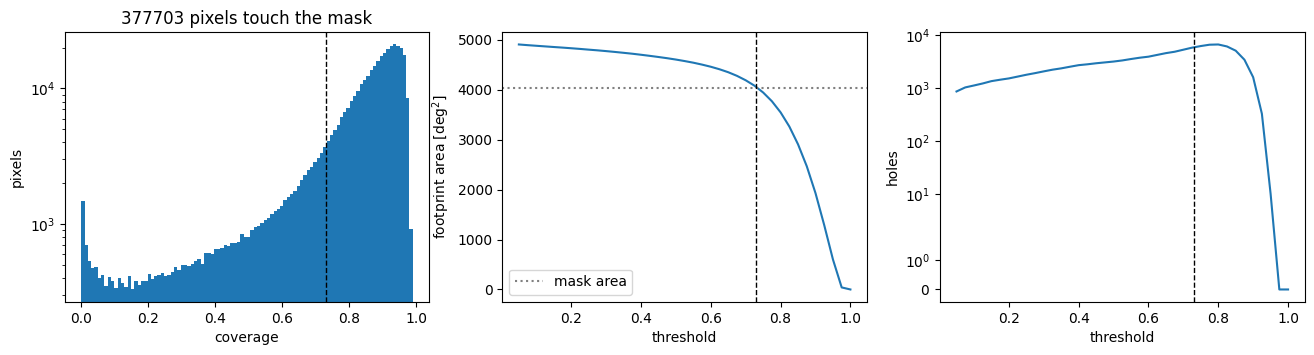

In [5]:
touched = coverage[coverage > 0]
thresholds = np.linspace(0.05, 1, 39)

fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(16, 3.5))
ax0.hist(touched, bins=100, log=True)
ax0.set(xlabel="coverage", ylabel="pixels", title=f"{touched.size} pixels touch the mask")

ax1.plot(thresholds, [np.sum(coverage >= t) * pix_area for t in thresholds])
ax1.axhline(attrs["area_deg2"], color="gray", ls=":", label="mask area")
ax1.set(xlabel="threshold", ylabel="footprint area [deg$^2$]")
ax1.legend()

n_holes = [np.sum(np.all((coverage >= t)[neighbours] | (neighbours < 0), axis=0) & (coverage < t)) for t in thresholds]
ax2.plot(thresholds, n_holes)
ax2.set(xlabel="threshold", ylabel="holes", yscale="symlog")

for ax in (ax0, ax1, ax2):
    ax.axvline(threshold, color="k", ls="--", lw=1)

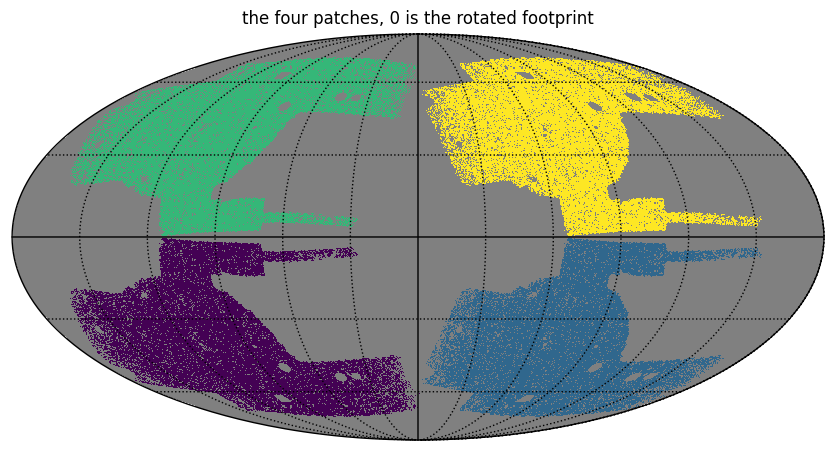

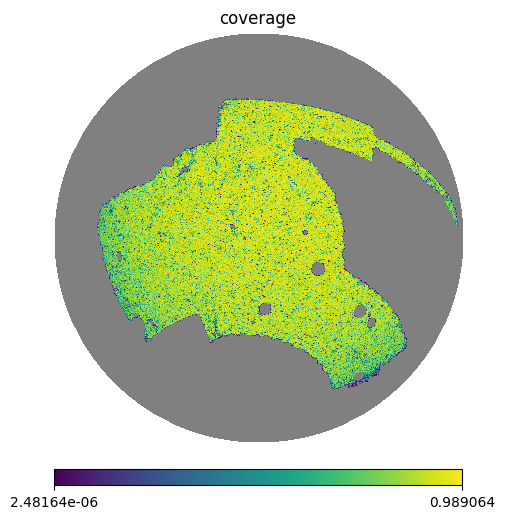

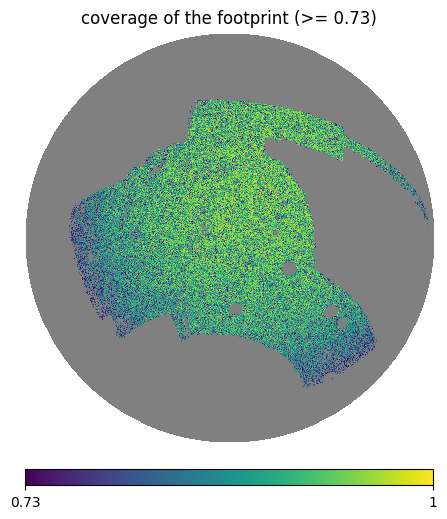

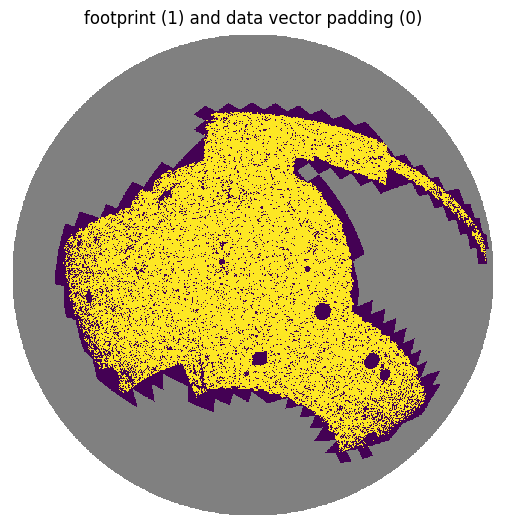

In [6]:
patch_map = np.full(n_pix, hp.UNSEEN)
for i, patch in enumerate(patches):
    patch_map[patch] = i
hp.mollview(patch_map, title="the four patches, 0 is the rotated footprint", cbar=False)
hp.graticule()

# centre of the rotated footprint, for the zooms below
lon, lat = hp.vec2ang(np.mean(hp.pix2vec(n_side, footprint), axis=1), lonlat=True)
centre = (float(np.ravel(lon)[0]), float(np.ravel(lat)[0]))

hp.orthview(np.where(coverage > 0, coverage, hp.UNSEEN), rot=centre, half_sky=True, title="coverage")
kept = np.full(n_pix, hp.UNSEEN)
kept[footprint] = coverage[footprint]
hp.orthview(kept, rot=centre, half_sky=True, title=f"coverage of the footprint (>= {threshold})", min=threshold, max=1)
padding = np.full(n_pix, hp.UNSEEN)
padding[hp.nest2ring(n_side, data_vec)] = 0
padding[footprint] = 1
hp.orthview(padding, rot=centre, half_sky=True, title="footprint (1) and data vector padding (0)", cbar=False)

## Survey values and the config

The data-derived values of the config next to DES's numbers (`3x2pt_pipeline_public.ipynb` for R and the area, the
methods paper for m), with R from the cache, then `values --check`, which writes nothing.

In [7]:
survey = conf["survey"]
shear = survey["metacal"]["shear_bias"]["multiplicative"]
response = np.load(catalog.cache_file(conf, desy6.MAPS_FILES["metacal_response"]))
response_des = catalog_desy6.SOURCE_DES["response"][0]

print(f"Aeff = {survey['Aeff']:.4f} deg^2 (DES {catalog_desy6.AREA_DES})\n")
print(f"{'bin':9s} {'n_gal [arcmin^-2]':>18s} {'R':>9s} {'R (DES)':>9s} {'m mu':>9s} {'m (DES)':>8s} {'m sigma':>8s}")
for i, label in enumerate(used["metacal"]):
    k = files.get_z_bin_number(label) - 1
    print(
        f"{label:9s} {survey['metacal']['n_gal'][i] / 60**2:18.4f} {response[k]:9.6f} {response_des[k]:9.6f} "
        f"{shear['mu'][i]:9.5f} {catalog_desy6.M_MEAN_DES[k]:8.5f} {shear['sigma'][i]:8.5f}"
    )
for i, label in enumerate(used["maglim"]):
    print(f"{label:9s} {survey['maglim']['n_gal'][i] / 60**2:18.4f}")

try:
    desy6.main(["values", "--config", str(CONFIG), "--check"])
except SystemExit as error:
    print(f"values --check: STALE (exit {error.code}), run the step values")

Aeff = 4031.0359 deg^2 (DES 4031.036)

bin        n_gal [arcmin^-2]         R   R (DES)      m mu  m (DES)  m sigma
metacal1              2.0650  0.856143  0.856143  -0.00340 -0.00340  0.00578
metacal2              2.1210  0.868506  0.868506   0.00646  0.00646  0.00662
metacal3              2.1327  0.819427  0.819427   0.01594  0.01594  0.00594
metacal4              2.2730  0.691769  0.691769   0.00170  0.00170  0.01220
maglim1               0.1129
maglim3               0.0862
maglim4               0.1088
maglim5               0.0849
maglim6               0.0860


26-11-20 10:57:22     desy6.py INF   metacal (metacal_count): n_gal = [2.06495149 2.12099527 2.13265971 2.27298886] arcmin^-2, in the footprint [0.89433721 0.8953978  0.89861924 0.90347238] (mask 0.8893) 


26-11-20 10:57:22     desy6.py INF   maglim (maglim_count): n_gal = [0.11288102 0.08139856 0.08620876 0.10876985 0.08489927 0.08600807] arcmin^-2, in the footprint [0.89100035 0.89106968 0.89160721 0.89186214 0.89143391 0.89346049] (mask 0.8893) 


26-11-20 10:57:23 catalog_desy INF   m prior from 80760 samples: mu = [-0.00339767  0.0064552   0.01593935  0.00169811], sigma = [0.00578436 0.00662382 0.00593803 0.01220025] (DES mu [-0.0034, 0.00646, 0.01594, 0.0017]) 


26-11-20 10:57:23     desy6.py INF   Aeff = 4031.036 deg^2, footprint 4055.2 deg^2 


26-11-20 10:57:23     desy6.py INF   configs/desy6/v1/default.yaml: all 5 marked values are up to date 


## Maps

The cached maps of the step `maps`, all survey bins. The mean shear is not subtracted, as in Y3; it is printed here
next to the per-pixel rms. For Y3 it was about 1.5% of the rms.

In [8]:
gamma, source_count, lens_count = (
    np.load(catalog.cache_file(conf, desy6.MAPS_FILES[key])) for key in ("metacal_gamma", "metacal_count", "maglim_count")
)  # (n_pix, 4, 2), (n_pix, 4), (n_pix, 6) raw

# the lens weight maps of the pixel file, in footprint order; the observation is the raw count times w
with h5py.File(REPO / conf["files"]["pixels"], "r") as f:
    lens_w_info = f["maglim/systematics"].attrs["info"]
    lens_w, lens_w_filled = (
        np.stack([f[f"maglim/systematics/{key}/{label}"][:] for label in survey_labels["maglim"]], axis=-1)
        for key in ("map", "filled")
    )
lens_w = lens_w.astype(np.float64)
lens_corrected = np.zeros(lens_count.shape)
lens_corrected[footprint] = lens_count[footprint] * lens_w

for i, label in enumerate(survey_labels["metacal"]):
    n = source_count[:, i]
    g = gamma[footprint, i]
    mean = np.average(g, weights=n[footprint], axis=0)
    rms = np.sqrt(np.average(g**2, weights=n[footprint], axis=0))
    print(
        f"{label}: {n[footprint].sum() / n.sum():.4f} of {n.sum()} galaxies in the footprint, "
        f"mean (g1, g2) = ({mean[0]:+.2e}, {mean[1]:+.2e}), rms ({rms[0]:.3f}, {rms[1]:.3f})"
    )
for j, label in enumerate(survey_labels["maglim"]):
    n = lens_count[:, j]
    print(
        f"{label}: {n[footprint].sum() / n.sum():.4f} of {n.sum()} galaxies in the footprint, "
        f"corrected / raw there {lens_corrected[footprint, j].sum() / n[footprint].sum():.4f}"
    )

metacal1: 0.8943 of 33707071 galaxies in the footprint, mean (g1, g2) = (+1.41e-04, -3.88e-05), rms (0.029, 0.029)
metacal2: 0.8954 of 34580888 galaxies in the footprint, mean (g1, g2) = (-7.84e-06, +6.67e-05), rms (0.031, 0.031)
metacal3: 0.8986 of 34646416 galaxies in the footprint, mean (g1, g2) = (+1.95e-04, +2.10e-04), rms (0.030, 0.030)
metacal4: 0.9035 of 36727798 galaxies in the footprint, mean (g1, g2) = (+2.87e-04, -7.56e-05), rms (0.036, 0.036)
maglim1: 0.8910 of 1852538.0 galaxies in the footprint, corrected / raw there 0.9984
maglim2: 0.8911 of 1335294.0 galaxies in the footprint, corrected / raw there 0.9987
maglim3: 0.8916 of 1413738.0 galaxies in the footprint, corrected / raw there 0.9984
maglim4: 0.8919 of 1783834.0 galaxies in the footprint, corrected / raw there 0.9981
maglim5: 0.8914 of 1391521.0 galaxies in the footprint, corrected / raw there 0.9992
maglim6: 0.8935 of 1409280.0 galaxies in the footprint, corrected / raw there 0.9972


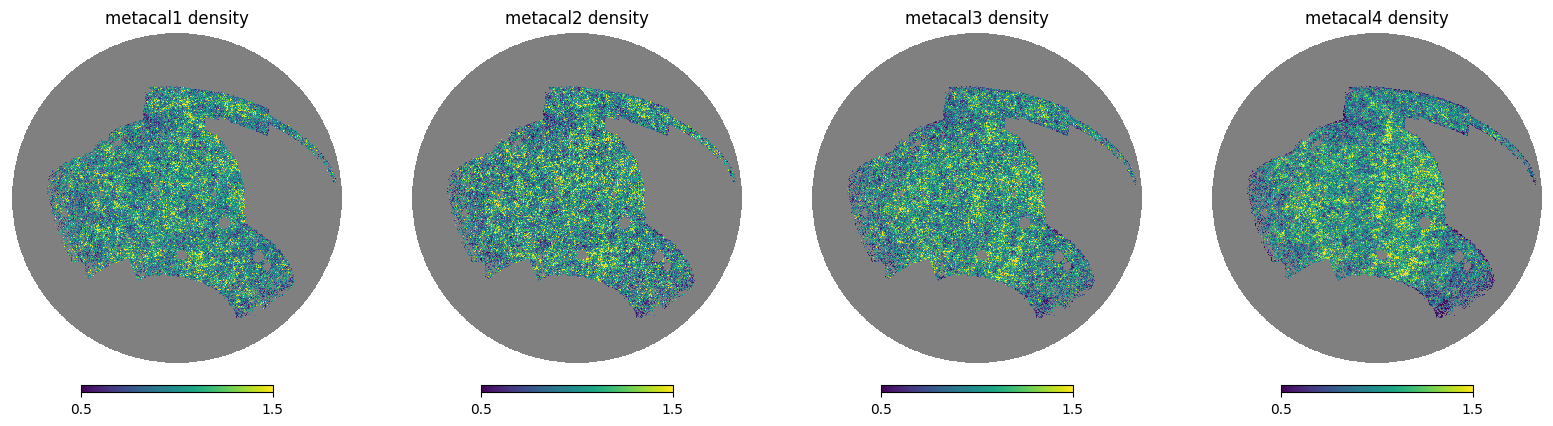

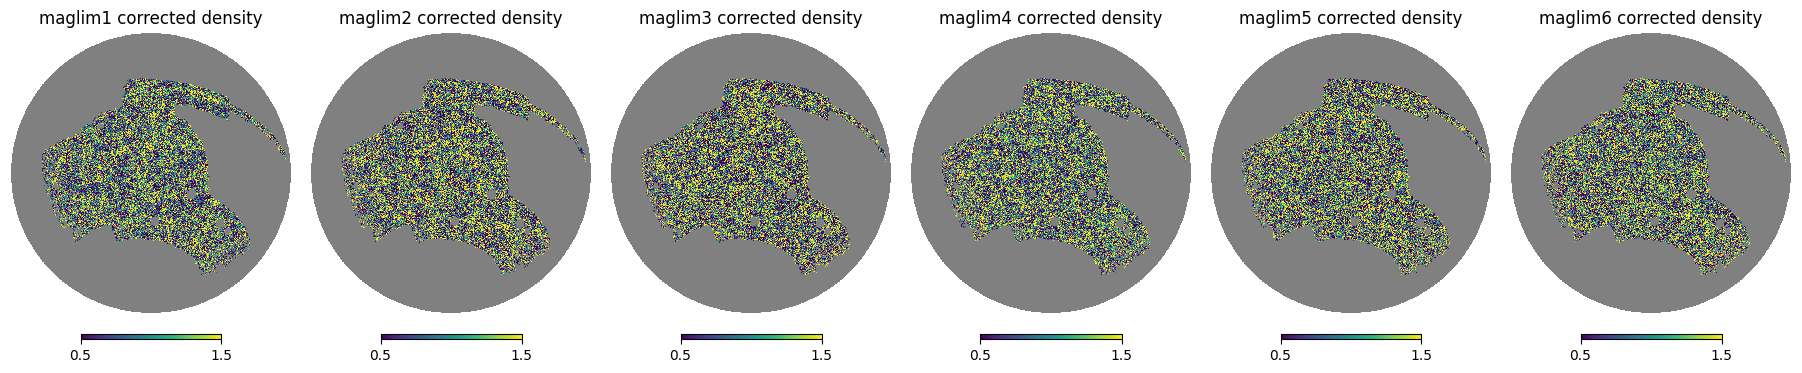

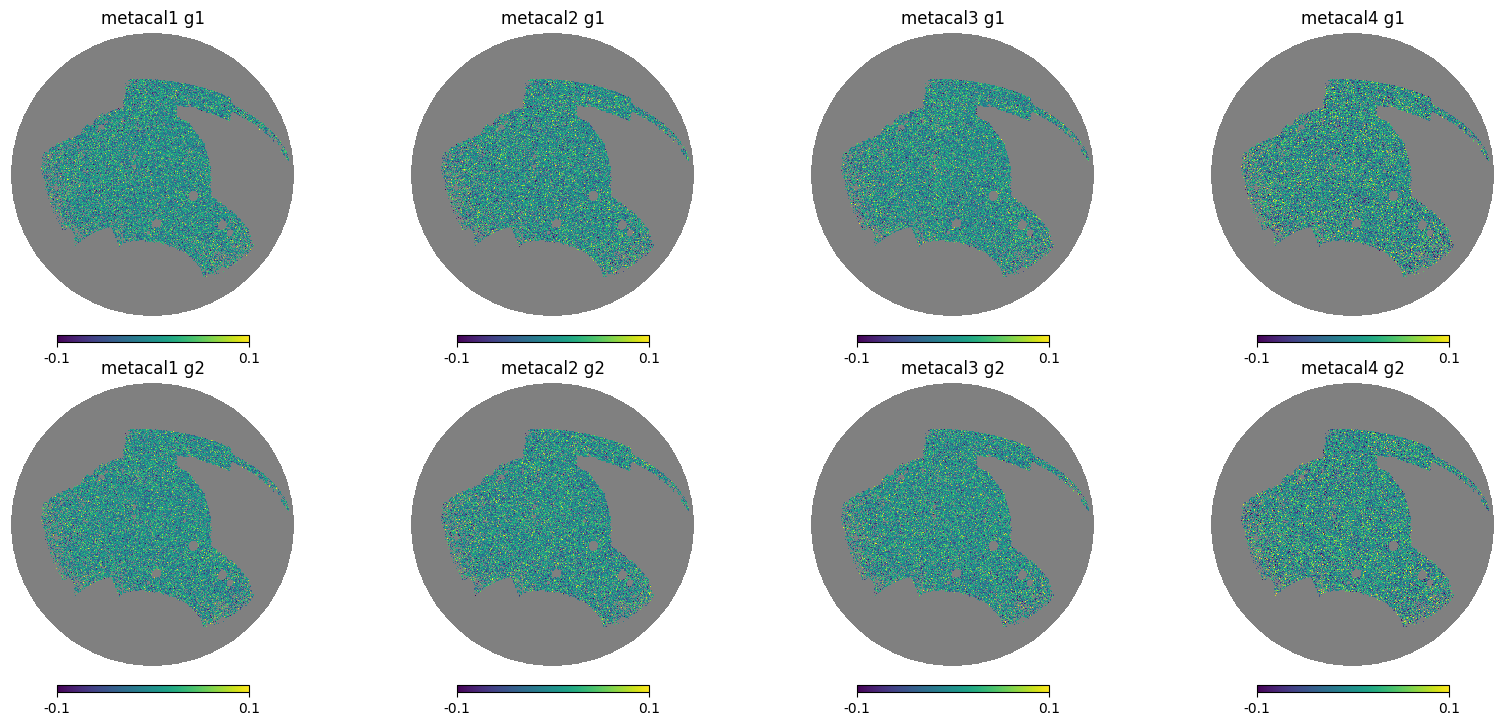

In [9]:
def show(values, title, sub, **kwargs):
    m = np.full(n_pix, hp.UNSEEN)
    m[footprint] = values[footprint]
    hp.orthview(m, rot=centre, half_sky=True, title=title, sub=sub, **kwargs)


# density relative to the footprint mean, per unit covered area
plt.figure(figsize=(16, 4))
for i, label in enumerate(survey_labels["metacal"]):
    n = source_count[:, i] / np.maximum(coverage, 1e-3)
    show(n / n[footprint].mean(), f"{label} density", (1, 4, i + 1), min=0.5, max=1.5)

plt.figure(figsize=(18, 4))
for j, label in enumerate(survey_labels["maglim"]):
    n = lens_corrected[:, j] / np.maximum(coverage, 1e-3)
    show(n / n[footprint].mean(), f"{label} corrected density", (1, 6, j + 1), min=0.5, max=1.5)

plt.figure(figsize=(16, 7))
for i, label in enumerate(survey_labels["metacal"]):
    for c in range(2):
        show(gamma[:, i, c], f"{label} g{c + 1}", (2, 4, c * 4 + i + 1), min=-0.1, max=0.1)

## MagLim weight maps

`maglim/systematics` of the pixel file. DES's fiducial lens weights come from ENet, an elastic-net regression of
each bin's density on the 19 survey-property maps (fit at nside 256, predicted at 1024); the release has them per
galaxy only. The step `pixels` turns them into w = 1/⟨F⟩ per base-patch pixel, F = 1/w being the contamination
(`catalog_desy6.maglim_weight_maps`). As in v18, w multiplies the observed counts (`apply_maglim_sys_map`) and stays
out of the forward model. The lens n_gal of the step `values` is the density of these corrected counts, so the clean
simulations match the observation in expectation.

The step gates the frame (the mean galaxy weight of each pixel follows w) and the normalization (the counts times w
sum to the per-galaxy weights). Here: the maps, n_gal against the corrected counts, and the counts against F. The raw
counts should follow F with slope 1 and the corrected ones should be flat. Large-scale structure dominates the
scatter, hence the jackknife errors over nside-8 regions.

ENet weights w = 1 / <F> of maglim_2024-11-07.hdf5 on the base patch, from the per-galaxy weights (catalog_desy6.maglim_weight_maps). They multiply the observed counts. map: base-patch order; data_vector: data_vec order, 0 in the padding; filled: no galaxy in the pixel, neighbour mean 

maglim1: w in [0.922, 1.136], std 0.0230, 447 pixels filled (0.14%); n_gal of the config / density of N w 1.000000
maglim2: w in [0.940, 1.103], std 0.0175, 1877 pixels filled (0.61%); not used
maglim3: w in [0.960, 1.092], std 0.0152, 1854 pixels filled (0.60%); n_gal of the config / density of N w 1.000000
maglim4: w in [0.875, 1.137], std 0.0281, 530 pixels filled (0.17%); n_gal of the config / density of N w 1.000000
maglim5: w in [0.950, 1.061], std 0.0128, 1285 pixels filled (0.42%); n_gal of the config / density of N w 1.000000
maglim6: w in [0.911, 1.206], std 0.0362, 1033 pixels filled (0.33%); n_gal of the config / density of N w 1.000000


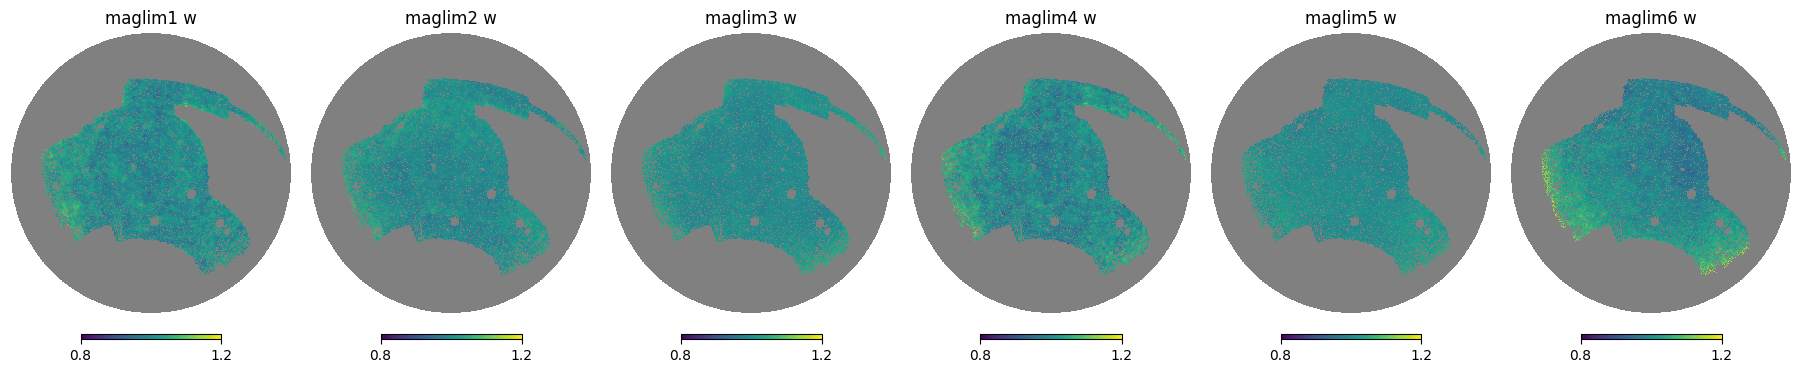

In [10]:
print(lens_w_info, "\n")
footprint_area = footprint.size * pix_area
n_gal = dict(zip(used["maglim"], conf["survey"]["maglim"]["n_gal"]))

for j, label in enumerate(survey_labels["maglim"]):
    w, filled = lens_w[:, j], lens_w_filled[:, j]
    density = lens_corrected[footprint, j].sum() / footprint_area
    check = f"n_gal of the config / density of N w {n_gal[label] / density:.6f}" if label in n_gal else "not used"
    print(
        f"{label}: w in [{w.min():.3f}, {w.max():.3f}], std {w.std():.4f}, {filled.sum()} pixels filled "
        f"({filled.mean():.2%}); {check}"
    )

plt.figure(figsize=(18, 4))
for j, label in enumerate(survey_labels["maglim"]):
    w_map = np.zeros(n_pix)
    w_map[footprint] = lens_w[:, j]
    show(w_map, f"{label} w", (1, 6, j + 1), min=0.8, max=1.2)

In [11]:
# jackknife regions: nside-8 pixels of the rotated frame
region = hp.ring2nest(n_side, footprint) // (n_side // 8) ** 2
regions = np.unique(region)
cov_fp = coverage[footprint]


def slope(n, F, weight):
    """Slope of n / <n> against F / <F>, weighted least squares."""
    x, y = F / np.average(F, weights=weight), n / np.average(n, weights=weight)
    x_mean, y_mean = np.average(x, weights=weight), np.average(y, weights=weight)
    return np.sum(weight * (x - x_mean) * (y - y_mean)) / np.sum(weight * (x - x_mean) ** 2)


def jackknife(n, F):
    full = slope(n, F, cov_fp)
    jk = np.array([slope(n[region != r], F[region != r], cov_fp[region != r]) for r in regions])
    return full, np.sqrt((regions.size - 1) * np.mean((jk - jk.mean()) ** 2))


print(f"slope of the counts per covered area against F = 1 / w, {regions.size} jackknife regions")
print(f"{'':10s}{'raw (1)':>17s}{'corrected (0)':>19s}")
for j, label in enumerate(survey_labels["maglim"]):
    F = 1 / lens_w[:, j]
    raw = lens_count[footprint, j] / cov_fp
    (s, e), (s_corr, e_corr) = jackknife(raw, F), jackknife(raw * lens_w[:, j], F)
    print(f"{label:10s}{s:9.3f} +- {e:.3f}{s_corr:+11.3f} +- {e_corr:.3f}")

slope of the counts per covered area against F = 1 / w, 132 jackknife regions
                    raw (1)      corrected (0)


maglim1       1.220 +- 0.208     +0.211 +- 0.209


maglim2       1.115 +- 0.268     +0.109 +- 0.270


maglim3       1.374 +- 0.277     +0.375 +- 0.280


maglim4       1.019 +- 0.118     +0.017 +- 0.120


maglim5       1.147 +- 0.325     +0.157 +- 0.327


maglim6       0.908 +- 0.079     -0.095 +- 0.082


## Noise file

The shape catalog per source bin, from the first 2 million rows of each: the response-corrected ellipticities and
the weights that the `count` shape-noise model resamples.

metacal1: 33707071 galaxies (count map 33707071), weighted rms e/R = [0.27108963 0.27073164]
metacal2: 34580888 galaxies (count map 34580888), weighted rms e/R = [0.28638426 0.28611009]


metacal3: 34646416 galaxies (count map 34646416), weighted rms e/R = [0.28109893 0.28068298]
metacal4: 36727798 galaxies (count map 36727798), weighted rms e/R = [0.34208952 0.34105455]


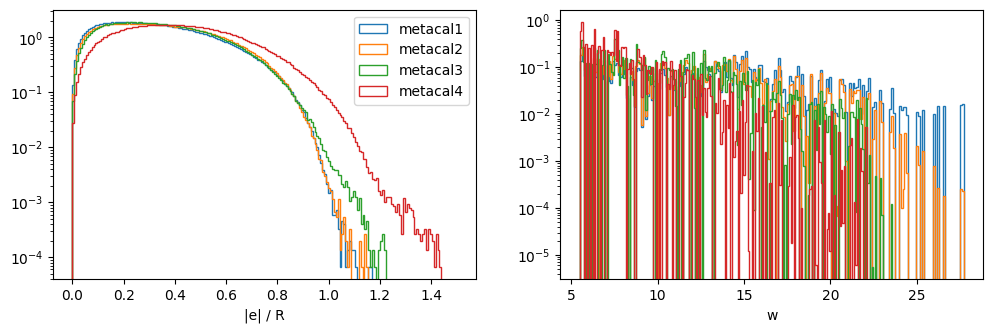

In [12]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 3.5))
with h5py.File(REPO / conf["files"]["noise"], "r") as f:
    for i, label in enumerate(survey_labels["metacal"]):
        cat = f[f"{label}/cat"]
        sample = cat[:2_000_000].astype(np.float64)
        e_abs, w = np.hypot(sample[:, 0], sample[:, 1]), sample[:, 2]
        rms = np.sqrt(np.average(sample[:, :2] ** 2, axis=0, weights=w))
        print(f"{label}: {cat.shape[0]} galaxies (count map {source_count[:, i].sum()}), weighted rms e/R = {rms}")
        ax0.hist(e_abs, bins=200, range=(0, 1.5), histtype="step", density=True, label=label)
        ax1.hist(w, bins=200, histtype="step", density=True, label=label)
ax0.set(xlabel="|e| / R", yscale="log")
ax1.set(xlabel="w", yscale="log")
ax0.legend()

## Shear convention: κ_E × δ_g and κ_B × δ_g

The Y3 conventions (e1 +1, e2 −1, the ψ rotation of `catalog.py`) are reused for Y6 until this test passes; for Y3
the same test validated them. κ_E and κ_B come from the footprint-masked shear maps through `lensing.mode_removal`,
as on the observation path; δ_g is the corrected MagLim count (raw times w) per covered area. Expected:

- κ_E × δ_g **positive** where the lens bin lies in front of the source bin. A flip of both e1 and e2 makes it
  negative; a wrong e2 parity pushes it towards zero.
- κ_B × δ_g **null**. A wrong or missing ψ rotation shows up here (−3 to −6σ per band for Y3 without it).

The E/B power alone cannot decide the overall sign. The errors are Gaussian (Knox) from the measured pseudo-spectra,
with the footprint's f_sky, so they ignore the mode coupling between neighbouring bands.

In [13]:
hp_datapath = str(REPO / conf["files"]["healpy_data"])
_, gamma2kappa_fac, _ = lensing.get_kaiser_squires_factors(3 * n_side - 1)
f_sky = in_footprint.mean()
l_max = 3 * n_side - 1
band_edges = np.array([30, 60, 100, 160, 250, 400, 630, 1000])
ell = np.arange(l_max + 1)
n_modes = np.array([np.sum(2 * ell[(ell >= lo) & (ell < hi)] + 1) for lo, hi in zip(band_edges[:-1], band_edges[1:])])


def footprint_only(m):
    """The map inside the footprint with its mean there removed, zero outside."""
    return np.where(in_footprint, m - m[in_footprint].mean(), 0.0)


def bands(cl):
    return np.array([cl[(ell >= lo) & (ell < hi)].mean() for lo, hi in zip(band_edges[:-1], band_edges[1:])])


kappa = {}
for label in used["metacal"]:
    i_survey = survey_labels["metacal"].index(label)
    g1, g2 = (np.where(in_footprint, gamma[:, i_survey, c], 0.0) for c in range(2))
    k_E, k_B = lensing.mode_removal(g1, g2, gamma2kappa_fac, n_side, hp_datapath=hp_datapath, keep_b_mode=True)
    kappa[label] = {"E": footprint_only(k_E.astype(np.float64)), "B": footprint_only(k_B.astype(np.float64))}

delta = {}
for label in used["maglim"]:
    n = lens_corrected[:, survey_labels["maglim"].index(label)]
    n_bar = n[in_footprint].sum() / coverage[in_footprint].sum()
    delta[label] = footprint_only(n / (n_bar * np.maximum(coverage, 1e-3)) - 1)

# band-averaged pseudo-spectra; the Knox error of a cross spectrum needs both autos
auto_kappa = {(label, mode): bands(hp.anafast(k[mode], lmax=l_max)) for label, k in kappa.items() for mode in "EB"}
auto_delta = {label: bands(hp.anafast(d, lmax=l_max)) for label, d in delta.items()}
cross = {}
for source, k in kappa.items():
    for lens, d in delta.items():
        for mode in "EB":
            cl = bands(hp.anafast(k[mode], d, lmax=l_max))
            sigma = np.sqrt((auto_kappa[source, mode] * auto_delta[lens] + cl**2) / (f_sky * n_modes))
            cross[source, lens, mode] = (cl, sigma)
print(f"f_sky = {f_sky:.4f}, {len(cross)} cross spectra in {len(n_modes)} bands")

f_sky = 0.0983, 40 cross spectra in 7 bands


pair                   E S/N   B S/N  B chi2/dof  lens in front
metacal1 x maglim1      15.3     2.1    7.6 / 7  yes
metacal1 x maglim3       3.3     0.8    3.7 / 7  no
metacal1 x maglim4       1.4    -0.7    6.6 / 7  no
metacal1 x maglim5       2.1     1.1    3.2 / 7  no
metacal1 x maglim6       1.4     1.7   10.3 / 7  no
metacal2 x maglim1      33.0    -0.4    7.7 / 7  yes
metacal2 x maglim3       3.9    -0.3    4.3 / 7  no
metacal2 x maglim4       2.6     0.6    4.4 / 7  no
metacal2 x maglim5       1.9    -0.1    5.4 / 7  no
metacal2 x maglim6       3.1    -0.6    4.3 / 7  no
metacal3 x maglim1      51.1    -0.3    1.9 / 7  yes
metacal3 x maglim3      20.8    -0.6    1.8 / 7  yes
metacal3 x maglim4       9.7    -0.2    2.7 / 7  yes


metacal3 x maglim5       6.3    -1.5    4.5 / 7  no
metacal3 x maglim6       4.0    -1.4    4.7 / 7  no
metacal4 x maglim1      48.1     0.4   10.0 / 7  yes
metacal4 x maglim3      31.0    -0.6    5.8 / 7  yes
metacal4 x maglim4      26.3    -0.6    2.1 / 7  yes
metacal4 x maglim5      17.6    -1.2    5.5 / 7  yes
metacal4 x maglim6      12.7    -1.0    2.6 / 7  yes


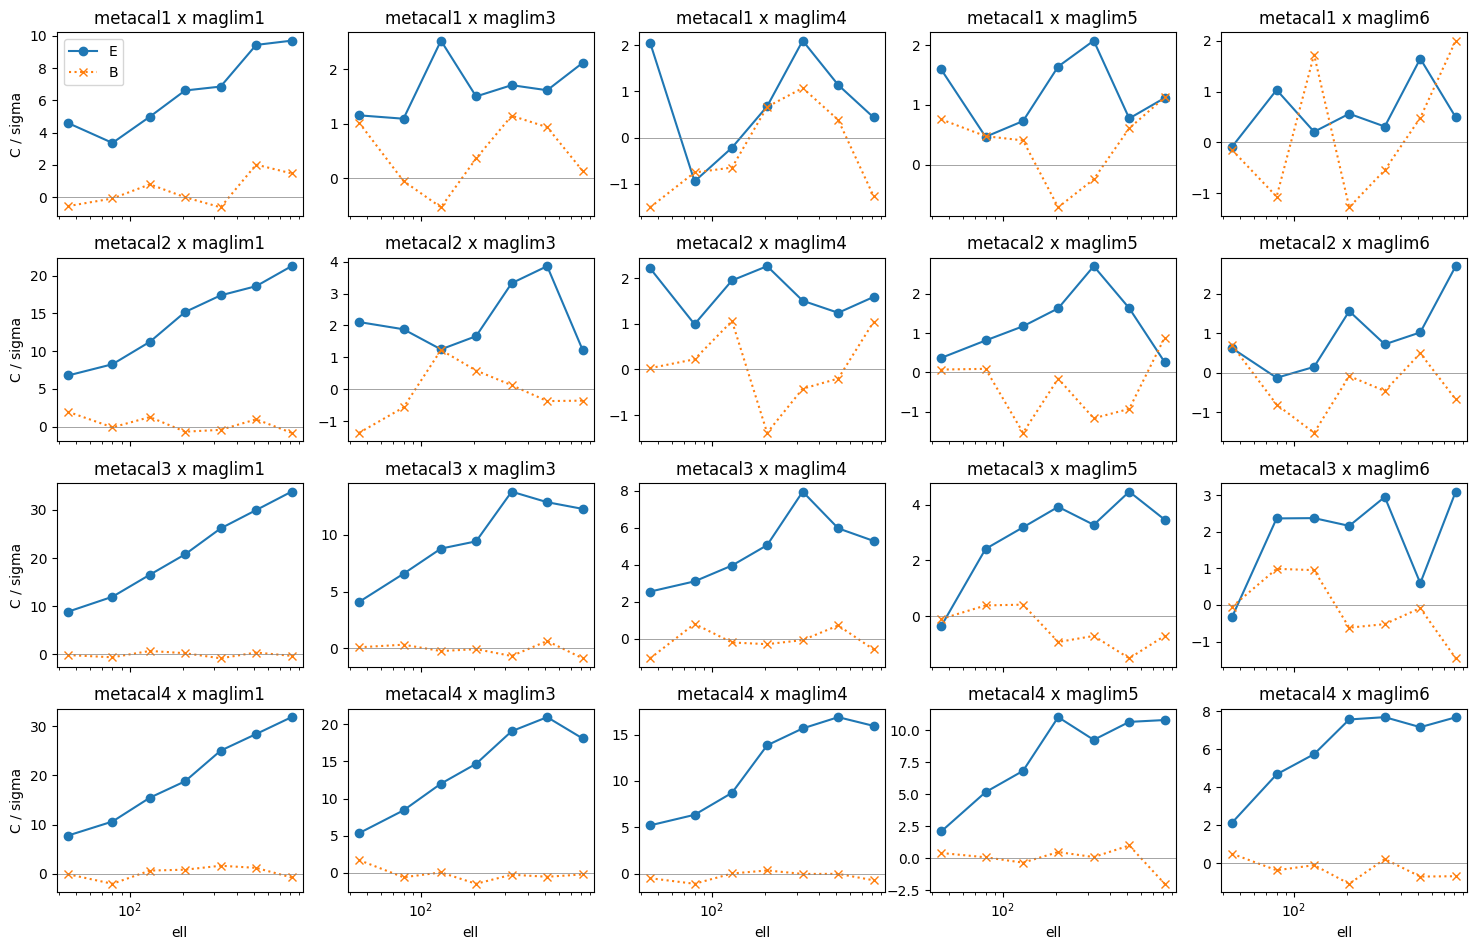

In [14]:
band_centres = 0.5 * (band_edges[:-1] + band_edges[1:])
sources, lenses = list(kappa), list(delta)


def combined(cl, sigma):
    """Inverse-variance weighted mean amplitude over the bands, in units of its error."""
    return np.sum(cl / sigma**2) / np.sqrt(np.sum(1 / sigma**2))


print(f"{'pair':20s} {'E S/N':>7s} {'B S/N':>7s} {'B chi2/dof':>11s}  lens in front")
fig, axes = plt.subplots(len(sources), len(lenses), figsize=(3 * len(lenses), 2.4 * len(sources)), sharex=True)
for r, source in enumerate(sources):
    for c, lens in enumerate(lenses):
        (cl_E, sigma_E), (cl_B, sigma_B) = cross[source, lens, "E"], cross[source, lens, "B"]
        chi2_B = np.sum((cl_B / sigma_B) ** 2)
        front = "yes" if mean_z[lens] < mean_z[source] else "no"
        print(
            f"{source + ' x ' + lens:20s} {combined(cl_E, sigma_E):7.1f} {combined(cl_B, sigma_B):7.1f} "
            f"{chi2_B:6.1f} / {len(n_modes)}  {front}"
        )

        ax = axes[r, c]
        ax.plot(band_centres, cl_E / sigma_E, "o-", label="E")
        ax.plot(band_centres, cl_B / sigma_B, "x:", label="B")
        ax.axhline(0, color="gray", lw=0.5)
        ax.set(xscale="log", title=f"{source} x {lens}")
        if c == 0:
            ax.set_ylabel("C / sigma")
        if r == len(sources) - 1:
            ax.set_xlabel("ell")
axes[0, 0].legend()
fig.tight_layout()

## Source clustering bias

The table of the step `sc_bias`: for every grid cosmology, and for `fiducial_bench` under the key `fiducial`, the b of
each source bin whose Poisson-sampled counts reproduce the one-point function of the observed counts
(`source_clustering_bias.fit_bias_table`). The arm `contam` imprints the imaging systematics of the step `systematics`
on the model density, the arm `clean` does not. v1 reads the per-cosmology b of `contam` (shape-noise bias `fixed`).
v2 reads only its `fiducial` row, as the anchor κ_i = b_i σ8 of the bias `prior`, which draws b_i = A_sc κ_i / σ8
with A_sc ~ U[0.5, 1.5].

The first figure needs `source_count` from the section Maps; the rest reads only tracked files.

In [ ]:
# v2 reads the anchor of its bias "prior" from the same table
conf_v2 = files.load_config(str(REPO / "configs/desy6/v2/v2.yaml"))
bsc_sigma8 = np.array(conf_v2["analysis"]["modelling"]["lensing"]["shape_noise"]["bsc_sigma8"])
asc_prior = conf_v2["analysis"]["grid"]["priors"]["Asc"]
s8_fid = conf_v2["analysis"]["fiducial"]["s8"]

sc_bias, sc_loss, sc_stat, sc_keys = {}, {}, {}, {}
with h5py.File(REPO / conf["files"]["metacal_bias"], "r") as f:
    for arm in f:
        sc_keys[arm] = [k.decode() if isinstance(k, bytes) else str(k) for k in f[arm]["keys"][:]]
        # the biases are one dataset per key, the diagnostics are stacked in the order of "keys"
        sc_bias[arm] = np.array([f[arm][k][:] for k in sc_keys[arm]])
        sc_loss[arm], sc_stat[arm] = f[arm]["loss"][:], f[arm]["stat"][:]
        print(f"{arm}: {len(sc_keys[arm])} keys, systematics {f[arm].attrs['systematics_label']!r}")
assert sc_keys["clean"] == sc_keys["contam"]
keys = np.array(sc_keys["contam"])
i_fid = int(np.flatnonzero(keys == "fiducial")[0])
is_grid = keys != "fiducial"

# sigma8 and w0 of the grid keys, from the CosmoGridV1 metainfo
grid_info = cosmogrid.get_cosmo_params_info(str(REPO / conf["files"]["meta_info"]), simset="grid")
row = {scb.cosmo_key(p): i for i, p in enumerate(grid_info["path_par"])}
grid_params = grid_info[[row[k] for k in keys[is_grid]]]
s8, w0 = grid_params["s8"].astype(np.float64), grid_params["w0"].astype(np.float64)

b_fid = sc_bias["contam"][i_fid]
print(f"\nfiducial b: contam {np.round(b_fid, 4)}, clean {np.round(sc_bias['clean'][i_fid], 4)}")
print(f"b sigma8 at the fiducial {np.round(b_fid * s8_fid, 4)}, v2 bsc_sigma8 {np.round(bsc_sigma8, 4)}")
print(f"quantile of the fiducial b in the grid: {np.round(np.mean(sc_bias['contam'][is_grid] < b_fid, axis=0), 3)}")
print(f"contam / clean, grid median: {np.round(np.median(sc_bias['contam'] / sc_bias['clean'], axis=0), 3)}")
loss = sc_loss["contam"]
print(
    f"loss (contam): fiducial {np.round(loss[i_fid], 3)}, "
    f"grid median {np.round(np.median(loss[is_grid], axis=0), 3)}, max {np.round(loss[is_grid].max(axis=0), 3)}"
)

In [ ]:
# the target of the fit, from source_count of the section Maps (the cache of the step maps)
target, n_bar, _ = scb.build_target(conf, count_map=source_count)
centres = scb._bin_centres_1pt(len(target[0]))

fig, axes = plt.subplots(2, len(used["metacal"]), figsize=(16, 6), sharex="col")
for i, label in enumerate(used["metacal"]):
    for ax in axes[:, i]:
        for stat in sc_stat["contam"][is_grid][::25, i]:
            ax.plot(centres, stat, color="lightgray", lw=0.4)
        ax.plot(centres, target[i], color="k", lw=1.5, label="DES Y6")
        for arm, ls in (("contam", "--"), ("clean", ":")):
            ax.plot(centres, sc_stat[arm][i_fid, i], ls=ls, lw=1.5, label=f"{arm}, b = {sc_bias[arm][i_fid, i]:.3f}")
    # up to where the observation and the fiducial fit have both run out
    x_max = max(
        centres[np.searchsorted(np.cumsum(h) / np.sum(h), 0.9999)] for h in (target[i], sc_stat["contam"][i_fid, i])
    )
    axes[0, i].set(title=label, xlim=(0, x_max))
    axes[1, i].set(xlabel="galaxies per pixel", yscale="log", ylim=(0.5, None))
axes[0, 0].set_ylabel("pixels")
axes[1, 0].set_ylabel("pixels")
axes[0, 0].legend(fontsize=8)
fig.suptitle("fits on fiducial_bench; grey: every 25th grid fit (contam)")
fig.tight_layout()

### The σ8 law of v2

Every b is fit to the same observed histogram. Beyond the Poisson noise, the model sets the width of that histogram
through b times the pixel-scale rms of the matter density in the bin, so b falls as that rms grows, roughly as 1/σ8.
v2's prior assumes exactly this law.

Top: the fits against σ8, with v2's band A_sc κ_i / σ8 and its centre A_sc = 1, which passes through the fiducial fit
by construction. Bottom: the amplitude each fit implies, b_i σ8 / κ_i, which would be 1 everywhere if the law were
exact. The colour is w0: σ8 is the amplitude at z = 0, while the histogram follows the amplitude at the source
redshifts, which depends on the growth history.

In [ ]:
b_grid = sc_bias["contam"][is_grid]
implied = b_grid * s8[:, None] / bsc_sigma8
s8_line = np.linspace(s8.min(), s8.max(), 200)

fig, axes = plt.subplots(2, len(used["metacal"]), figsize=(17, 7), sharex=True, constrained_layout=True)
for i, label in enumerate(used["metacal"]):
    ax = axes[0, i]
    ax.fill_between(
        s8_line,
        asc_prior[0] * bsc_sigma8[i] / s8_line,
        asc_prior[1] * bsc_sigma8[i] / s8_line,
        color="C0",
        alpha=0.15,
        label=f"v2 prior, $A_\\mathrm{{sc}}$ in {asc_prior}",
    )
    ax.plot(s8_line, bsc_sigma8[i] / s8_line, color="C0", label="$A_\\mathrm{sc} = 1$")
    points = ax.scatter(s8, b_grid[:, i], c=w0, s=2, cmap="coolwarm", zorder=10)
    ax.plot(s8_fid, b_fid[i], "k*", ms=10, zorder=20, label="fiducial")
    slope = np.polyfit(np.log(s8), np.log(b_grid[:, i]), 1)[0]
    ax.set(title=f"{label}: $b \\propto \\sigma_8^{{{slope:.2f}}}$")

    ax = axes[1, i]
    ax.axhspan(*asc_prior, color="C0", alpha=0.15)
    ax.axhline(1, color="C0")
    ax.scatter(s8, implied[:, i], c=w0, s=2, cmap="coolwarm", zorder=10)
    lo, hi = np.percentile(implied[:, i], [1, 99])
    ax.set(xlabel="$\\sigma_8$", title=f"1st to 99th percentile: {lo:.2f} to {hi:.2f}")
axes[0, 0].set_ylabel("$b$ (contam)")
axes[1, 0].set_ylabel("$b \\sigma_8 / \\kappa$ = implied $A_\\mathrm{sc}$")
axes[0, 0].legend(fontsize=8)
fig.colorbar(points, ax=axes, label="$w_0$", shrink=0.6)

inside = np.all((implied >= asc_prior[0]) & (implied <= asc_prior[1]), axis=1)
spread = implied.max(axis=1) / implied.min(axis=1)
print(f"implied A_sc, median per bin {np.round(np.median(implied, axis=0), 3)}")
print(f"all four bins inside the prior {asc_prior}: {inside.mean():.2%} of the grid")
print(
    f"max / min of the implied A_sc over the four bins: median {np.median(spread):.3f}, "
    f"99th percentile {np.percentile(spread, 99):.3f}"
)